# DDPG, TD3 and SAC comparison

This notebook performs the shared analysis for the smart-irrigation project. It compares convergence, stability and generalisation under the fixed experiment settings, while keeping missing agents as explicit placeholders until their results arrive.

**Comparison rule:** test-season outcomes are first averaged within each training seed. The reported mean and standard deviation are then calculated across the five independent seeds, so repeated climate years are not incorrectly treated as independent training runs.

## 1. Imports and fixed comparison settings

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

AGENTS = ["ddpg", "td3", "sac"]
AGENT_LABELS = {"ddpg": "DDPG", "td3": "TD3", "sac": "SAC"}
AGENT_COLOURS = {"ddpg": "#1565C0", "td3": "#6A1B9A", "sac": "#2E7D32"}
EXPECTED_SEEDS = {11, 22, 33, 44, 55}
EXPECTED_TEST_YEARS = {2021, 2022, 2023, 2024}
EXPECTED_TRAINING_STEPS = 100_000
BOOTSTRAP_REPLICATES = 10_000
BOOTSTRAP_SEED = 6008

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

## 2. Locate the repository and result files

Run this notebook from the repository root or from `notebooks/`. The loader supports the current DDPG and SAC filenames and several reasonable TD3 equivalents. Missing files are reported without stopping the notebook.

In [2]:
def find_repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "outputs").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError(
        "Repository root not found. In Colab, clone/open the repository and change into it first."
    )

ROOT = find_repo_root()
OUTPUT_ROOT = ROOT / "outputs"
COMPARISON_DIR = OUTPUT_ROOT / "comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
print("Repository root:", ROOT)
print("Comparison outputs:", COMPARISON_DIR)

Repository root: /workspace/scratch/832d5da6d771
Comparison outputs: /workspace/scratch/832d5da6d771/outputs/comparison


In [3]:
FILE_PATTERNS = {
    "ddpg": {
        "learning": [["final/ddpg_learning_curves.csv"]],
        "test": [["final/ddpg_test_results.csv"]],
        "robustness": [["final/ddpg_robustness_results.csv"]],
        "sensitivity": [["reward_sensitivity/ddpg_reward_sensitivity_results.csv"]],
    },
    "sac": {
        "learning": [["final/sac_learning_curves.csv"], ["final/sac_final_seed*_evaluations.csv"]],
        "test": [["final/sac_final_test_all_seeds.csv"], ["final/sac_final_seed*_test.csv"]],
        "robustness": [["robustness/sac_robustness_all_seeds.csv"], ["robustness/sac_robustness_seed*.csv"]],
        "sensitivity": [["reward_sensitivity/sac_reward_sensitivity_all.csv"]],
    },
    "td3": {
        "learning": [["final/td3_learning_curves.csv"], ["final/td3_final_seed*_evaluations.csv"], ["final/*evaluations.csv"]],
        "test": [["final/td3_test_results.csv"], ["final/td3_final_test_all_seeds.csv"], ["final/td3_final_seed*_test.csv"]],
        "robustness": [["final/td3_robustness_results.csv"], ["robustness/td3_robustness_all_seeds.csv"], ["robustness/*seed*.csv"]],
        "sensitivity": [["reward_sensitivity/td3_reward_sensitivity_results.csv"], ["reward_sensitivity/td3_reward_sensitivity_all.csv"]],
    },
}

def load_first_available(agent, result_kind):
    base = OUTPUT_ROOT / agent
    for pattern_group in FILE_PATTERNS[agent][result_kind]:
        paths = []
        for pattern in pattern_group:
            paths.extend(sorted(base.glob(pattern)))
        paths = list(dict.fromkeys(paths))
        if paths:
            frames = [pd.read_csv(path).assign(source_file=str(path.relative_to(ROOT))) for path in paths]
            frame = pd.concat(frames, ignore_index=True)
            if "agent" not in frame.columns:
                frame["agent"] = agent
            frame["agent"] = frame["agent"].fillna(agent).astype(str).str.lower()
            return frame, paths
    return pd.DataFrame(), []

results = {agent: {} for agent in AGENTS}
inventory_rows = []
for agent in AGENTS:
    for result_kind in ["learning", "test", "robustness", "sensitivity"]:
        frame, paths = load_first_available(agent, result_kind)
        results[agent][result_kind] = frame
        inventory_rows.append({
            "agent": AGENT_LABELS[agent], "result_kind": result_kind,
            "status": "loaded" if paths else "missing", "rows": len(frame),
            "files": "; ".join(str(path.relative_to(ROOT)) for path in paths),
        })

inventory = pd.DataFrame(inventory_rows)
display(inventory)
if (inventory["status"] == "missing").any():
    print("Missing inputs are placeholders. Rerun after the corresponding branch/results are merged.")

,agent,result_kind,status,rows,files
0,DDPG,learning,loaded,420,outputs/ddpg/final/ddpg_learning_curves.csv
1,DDPG,test,loaded,20,outputs/ddpg/final/ddpg_test_results.csv
2,DDPG,robustness,loaded,180,outputs/ddpg/final/ddpg_robustness_results.csv
3,DDPG,sensitivity,loaded,16,outputs/ddpg/reward_sensitivity/ddpg_reward_se...
4,TD3,learning,loaded,420,outputs/td3/final/td3_learning_curves.csv
5,TD3,test,loaded,20,outputs/td3/final/td3_test_results.csv
6,TD3,robustness,loaded,180,outputs/td3/final/td3_robustness_results.csv
7,TD3,sensitivity,loaded,16,outputs/td3/reward_sensitivity/td3_reward_sens...
8,SAC,learning,loaded,420,outputs/sac/final/sac_final_seed11_evaluations...
9,SAC,test,loaded,20,outputs/sac/final/sac_final_test_all_seeds.csv


## 3. Reproducibility and fairness audit

The audit checks the columns needed for a fair comparison, successful run status, duplicate seed–season records, the five fixed final seeds, held-out test years and the 100,000-step budget. It reports problems rather than silently discarding them.

In [4]:
REQUIRED_TEST_COLUMNS = {
    "agent", "seed", "split", "season_year", "training_steps",
    "discounted_return", "irrigation_mm", "days_below_target",
    "shortage_mm_days", "drainage_mm", "status",
}

def audit_test_frame(agent, frame):
    label = AGENT_LABELS[agent]
    if frame.empty:
        return {"agent": label, "ready": False, "issues": "final test file missing"}
    issues = []
    missing = sorted(REQUIRED_TEST_COLUMNS - set(frame.columns))
    if missing:
        issues.append("missing columns: " + ", ".join(missing))
        return {"agent": label, "ready": False, "issues": "; ".join(issues)}
    ok = frame.loc[frame["status"].eq("ok")].copy()
    if len(ok) != len(frame):
        issues.append(f"{len(frame) - len(ok)} non-ok rows")
    duplicates = ok.duplicated(["seed", "season_year"]).sum()
    if duplicates:
        issues.append(f"{duplicates} duplicate seed-season rows")
    seeds = set(pd.to_numeric(ok["seed"], errors="coerce").dropna().astype(int))
    years = set(pd.to_numeric(ok["season_year"], errors="coerce").dropna().astype(int))
    steps = set(pd.to_numeric(ok["training_steps"], errors="coerce").dropna().astype(int))
    if seeds != EXPECTED_SEEDS:
        issues.append(f"seeds={sorted(seeds)}; expected={sorted(EXPECTED_SEEDS)}")
    if years != EXPECTED_TEST_YEARS:
        issues.append(f"test years={sorted(years)}; expected={sorted(EXPECTED_TEST_YEARS)}")
    if steps != {EXPECTED_TRAINING_STEPS}:
        issues.append(f"training steps={sorted(steps)}; expected={[EXPECTED_TRAINING_STEPS]}")
    return {
        "agent": label, "ready": not issues, "rows": len(ok),
        "seeds": sorted(seeds), "test_years": sorted(years),
        "training_steps": sorted(steps), "issues": "; ".join(issues) or "none",
    }

audit = pd.DataFrame([audit_test_frame(agent, results[agent]["test"]) for agent in AGENTS])
display(audit)
audit.to_csv(COMPARISON_DIR / "comparison_input_audit.csv", index=False)

,agent,ready,rows,seeds,test_years,training_steps,issues
0,DDPG,True,20,"[11, 22, 33, 44, 55]","[2021, 2022, 2023, 2024]",[100000],none
1,TD3,True,20,"[11, 22, 33, 44, 55]","[2021, 2022, 2023, 2024]",[100000],none
2,SAC,True,20,"[11, 22, 33, 44, 55]","[2021, 2022, 2023, 2024]",[100000],none


## 4. Final held-out test comparison

Higher discounted return is better. For irrigation, dry days, shortage and drainage, lower values are better, but water use must be interpreted alongside plant-health penalties rather than optimised alone.

In [5]:
METRICS = [
    "discounted_return", "irrigation_mm", "days_below_target",
    "shortage_mm_days", "drainage_mm",
]

test_frames = []
for agent in AGENTS:
    frame = results[agent]["test"].copy()
    if frame.empty or not REQUIRED_TEST_COLUMNS.issubset(frame.columns):
        continue
    frame = frame.loc[frame["status"].eq("ok")].copy()
    frame["agent"] = agent
    for column in ["seed", "season_year", "training_steps", *METRICS]:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    test_frames.append(frame)

test_all = pd.concat(test_frames, ignore_index=True) if test_frames else pd.DataFrame()
if test_all.empty:
    print("No valid final test results are available yet.")
    seed_level = pd.DataFrame()
    final_summary = pd.DataFrame()
else:
    seed_level = test_all.groupby(["agent", "seed"], as_index=False)[METRICS].mean()
    summary_parts = []
    for metric in METRICS:
        part = seed_level.groupby("agent")[metric].agg(["mean", "std", "min", "max", "count"]).reset_index()
        part.insert(1, "metric", metric)
        summary_parts.append(part)
    final_summary = pd.concat(summary_parts, ignore_index=True)
    final_summary["agent"] = final_summary["agent"].map(AGENT_LABELS)
    final_summary["mean_sd"] = final_summary.apply(
        lambda row: f"{row['mean']:.3f} ± {row['std']:.3f}" if pd.notna(row["std"]) else f"{row['mean']:.3f}", axis=1
    )
    display(final_summary.pivot(index="agent", columns="metric", values="mean_sd"))
    seed_level.to_csv(COMPARISON_DIR / "final_test_seed_level.csv", index=False)
    final_summary.to_csv(COMPARISON_DIR / "final_test_summary.csv", index=False)

metric,days_below_target,discounted_return,drainage_mm,irrigation_mm,shortage_mm_days
agent,,,,,
DDPG,0.250 ± 0.177,-21.064 ± 0.316,37.910 ± 3.773,601.868 ± 6.891,0.584 ± 0.807
SAC,0.850 ± 1.342,-22.847 ± 0.359,53.393 ± 5.135,621.808 ± 6.795,1.851 ± 3.773
TD3,0.050 ± 0.112,-20.426 ± 0.295,33.452 ± 2.980,588.007 ± 4.824,0.070 ± 0.156


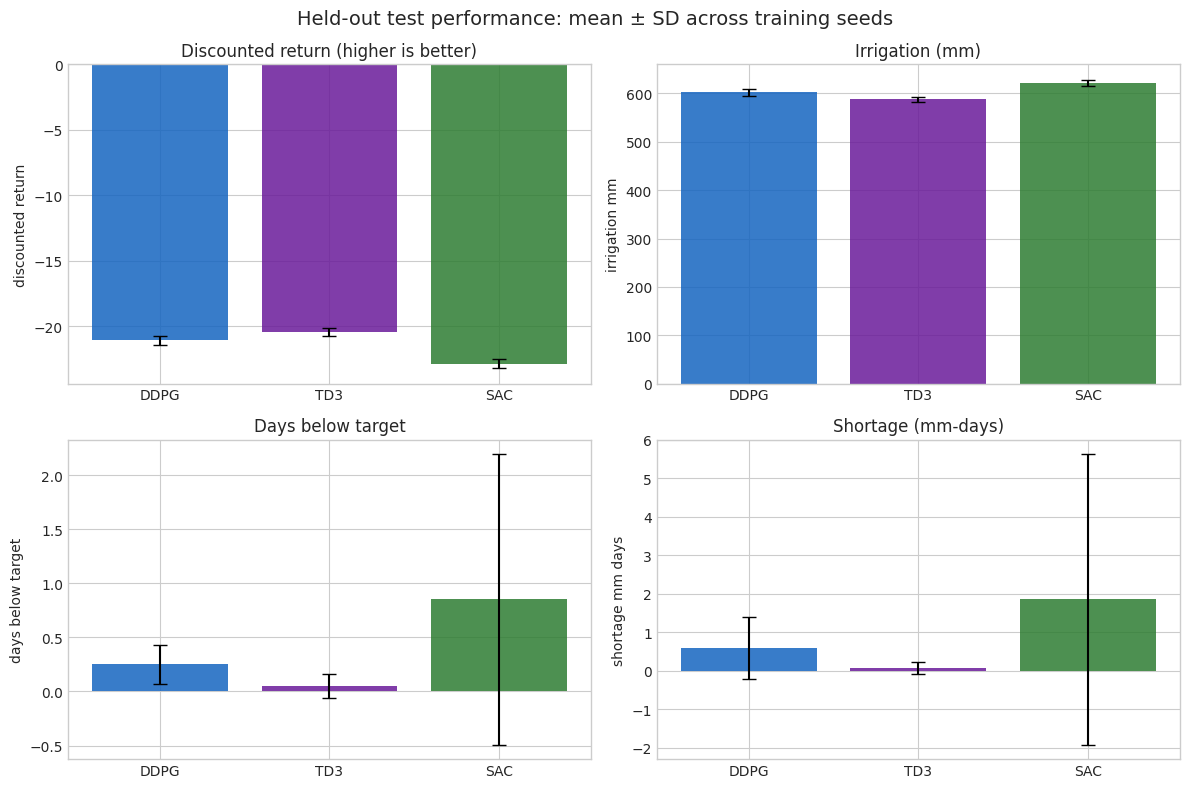

In [6]:
if not seed_level.empty:
    plot_metrics = ["discounted_return", "irrigation_mm", "days_below_target", "shortage_mm_days"]
    titles = ["Discounted return (higher is better)", "Irrigation (mm)", "Days below target", "Shortage (mm-days)"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, metric, title in zip(axes.flat, plot_metrics, titles):
        order = [agent for agent in AGENTS if agent in set(seed_level["agent"])]
        means = [seed_level.loc[seed_level["agent"].eq(agent), metric].mean() for agent in order]
        stds = [seed_level.loc[seed_level["agent"].eq(agent), metric].std(ddof=1) for agent in order]
        ax.bar([AGENT_LABELS[a] for a in order], means, yerr=stds, capsize=5, color=[AGENT_COLOURS[a] for a in order], alpha=0.85)
        ax.set_title(title)
        ax.set_ylabel(metric.replace("_", " "))
    fig.suptitle("Held-out test performance: mean ± SD across training seeds", fontsize=14)
    fig.tight_layout()
    fig.savefig(COMPARISON_DIR / "final_test_comparison.png", dpi=180, bbox_inches="tight")
    plt.show()

## 5. Generalisation across unseen climate years

This plot checks whether an algorithm's average result is driven by one unusually easy or difficult held-out season. Shading is the standard deviation across training seeds for each year.

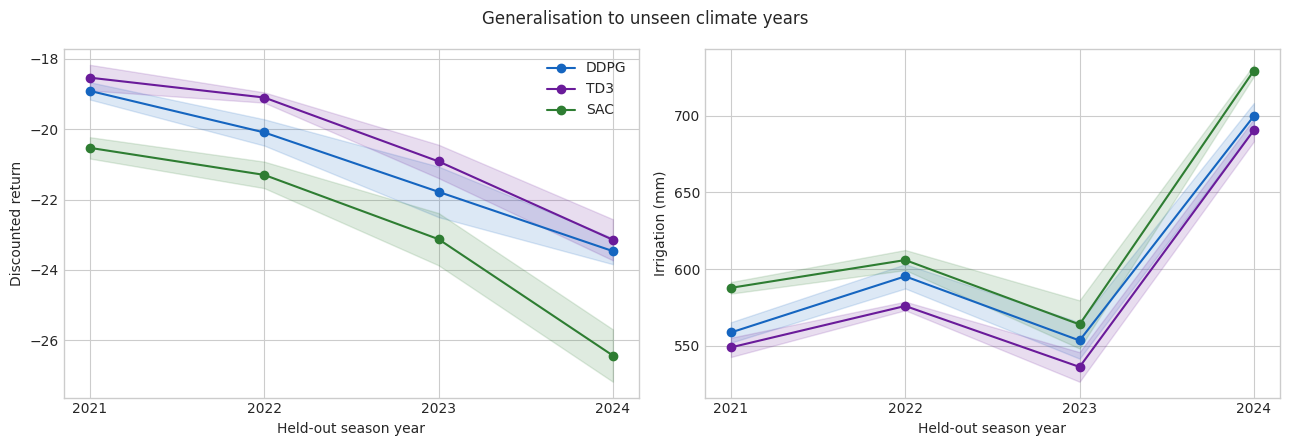

In [7]:
if not test_all.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for agent in AGENTS:
        subset = test_all.loc[test_all["agent"].eq(agent)]
        if subset.empty:
            continue
        by_year = subset.groupby("season_year").agg(
            return_mean=("discounted_return", "mean"), return_sd=("discounted_return", "std"),
            irrigation_mean=("irrigation_mm", "mean"), irrigation_sd=("irrigation_mm", "std"),
        ).reset_index()
        x = by_year["season_year"].to_numpy()
        for ax, mean_col, sd_col, ylabel in [
            (axes[0], "return_mean", "return_sd", "Discounted return"),
            (axes[1], "irrigation_mean", "irrigation_sd", "Irrigation (mm)"),
        ]:
            mean = by_year[mean_col].to_numpy()
            sd = by_year[sd_col].fillna(0).to_numpy()
            ax.plot(x, mean, marker="o", label=AGENT_LABELS[agent], color=AGENT_COLOURS[agent])
            ax.fill_between(x, mean - sd, mean + sd, alpha=0.15, color=AGENT_COLOURS[agent])
            ax.set_xlabel("Held-out season year")
            ax.set_ylabel(ylabel)
            ax.set_xticks(sorted(test_all["season_year"].dropna().unique().astype(int)))
    axes[0].legend()
    fig.suptitle("Generalisation to unseen climate years")
    fig.tight_layout()
    fig.savefig(COMPARISON_DIR / "test_year_generalisation.png", dpi=180, bbox_inches="tight")
    plt.show()

## 6. Convergence and training stability

Validation returns are averaged across validation seasons within each seed, then summarised across seeds at each evaluation step. Curves are descriptive: identical evaluation schedules are required before claiming one algorithm converges faster.

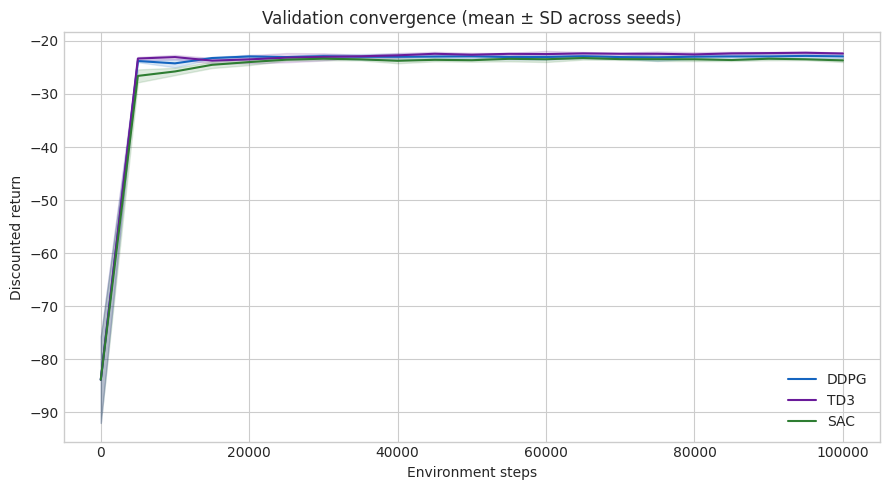

In [8]:
learning_frames = []
for agent in AGENTS:
    frame = results[agent]["learning"].copy()
    needed = {"seed", "training_steps", "discounted_return"}
    if frame.empty or not needed.issubset(frame.columns):
        continue
    if "status" in frame.columns:
        frame = frame.loc[frame["status"].eq("ok")]
    if "split" in frame.columns:
        frame = frame.loc[frame["split"].eq("validation")]
    frame["agent"] = agent
    learning_frames.append(frame)

if not learning_frames:
    print("No learning-curve files are available.")
else:
    learning_all = pd.concat(learning_frames, ignore_index=True)
    learning_seed = learning_all.groupby(["agent", "seed", "training_steps"], as_index=False)["discounted_return"].mean()
    learning_summary = learning_seed.groupby(["agent", "training_steps"])["discounted_return"].agg(["mean", "std", "count"]).reset_index()
    fig, ax = plt.subplots(figsize=(9, 5))
    for agent in AGENTS:
        curve = learning_summary.loc[learning_summary["agent"].eq(agent)].sort_values("training_steps")
        if curve.empty:
            continue
        x, mean = curve["training_steps"].to_numpy(), curve["mean"].to_numpy()
        sd = curve["std"].fillna(0).to_numpy()
        ax.plot(x, mean, label=AGENT_LABELS[agent], color=AGENT_COLOURS[agent])
        ax.fill_between(x, mean - sd, mean + sd, alpha=0.15, color=AGENT_COLOURS[agent])
    ax.set(title="Validation convergence (mean ± SD across seeds)", xlabel="Environment steps", ylabel="Discounted return")
    ax.legend()
    fig.tight_layout()
    fig.savefig(COMPARISON_DIR / "convergence_comparison.png", dpi=180, bbox_inches="tight")
    learning_summary.to_csv(COMPARISON_DIR / "convergence_summary.csv", index=False)
    plt.show()

## 7. Robustness comparison

Robustness scenarios are compared using `nominal_rescored_return` when available. This keeps the scoring rule fixed when the simulator is perturbed.

,agent,scenario,mean,std,count
0,ddpg,capacity_0.8,-33.902063,0.351068,5
1,ddpg,capacity_1.2,-30.800607,0.482216,5
2,ddpg,efficiency_0.75,-35.794204,0.461467,5
3,ddpg,efficiency_0.95,-29.268932,0.498688,5
4,ddpg,kc_0.9,-27.892729,0.400572,5
5,ddpg,kc_1.1,-36.818683,0.835511,5
6,ddpg,planting_minus_14d,-34.412139,0.481382,5
7,ddpg,planting_plus_14d,-30.323256,0.530408,5
8,ddpg,root_zone_0.6m,-35.873260,0.469035,5
9,sac,capacity_0.8,-35.761783,0.599081,5


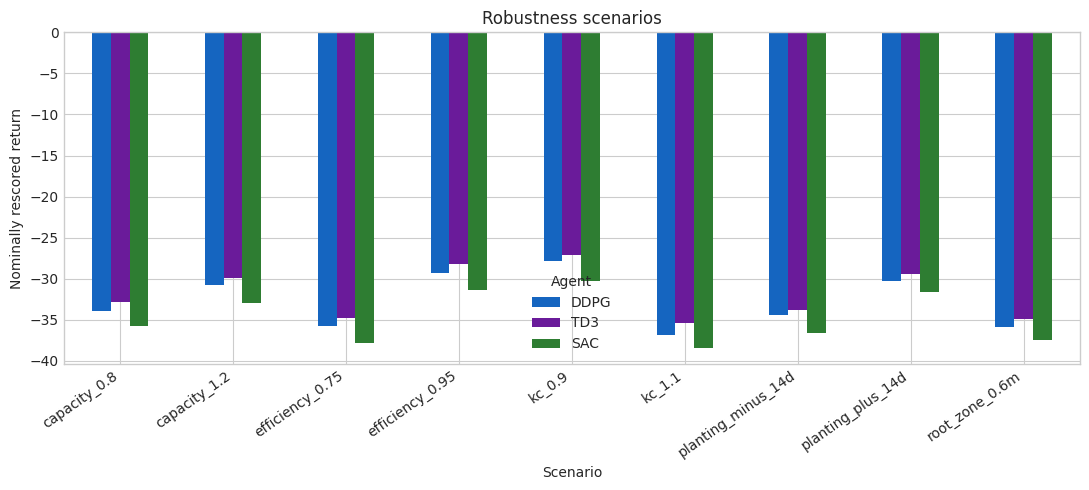

In [9]:
robust_frames = []
for agent in AGENTS:
    frame = results[agent]["robustness"].copy()
    if frame.empty or "scenario" not in frame.columns:
        continue
    metric = "nominal_rescored_return" if "nominal_rescored_return" in frame.columns else "discounted_return"
    if metric not in frame.columns:
        continue
    if "status" in frame.columns:
        frame = frame.loc[frame["status"].eq("ok")]
    frame["agent"] = agent
    frame["comparison_return"] = pd.to_numeric(frame[metric], errors="coerce")
    robust_frames.append(frame)

if not robust_frames:
    print("No robustness results are available.")
else:
    robustness_all = pd.concat(robust_frames, ignore_index=True)
    robustness_seed = robustness_all.groupby(["agent", "seed", "scenario"], as_index=False)["comparison_return"].mean()
    robustness_summary = robustness_seed.groupby(["agent", "scenario"])["comparison_return"].agg(["mean", "std", "count"]).reset_index()
    display(robustness_summary)
    pivot = robustness_summary.pivot(index="scenario", columns="agent", values="mean")
    pivot = pivot.reindex(columns=[a for a in AGENTS if a in pivot.columns])
    ax = pivot.rename(columns=AGENT_LABELS).plot(kind="bar", figsize=(11, 5), color=[AGENT_COLOURS[a] for a in pivot.columns])
    ax.set(title="Robustness scenarios", xlabel="Scenario", ylabel="Nominally rescored return")
    ax.legend(title="Agent")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / "robustness_comparison.png", dpi=180, bbox_inches="tight")
    robustness_summary.to_csv(COMPARISON_DIR / "robustness_summary.csv", index=False)
    plt.show()

## 8. Reward-sensitivity analysis

These experiments use shorter sensitivity-training runs, so they show whether conclusions change with reward weighting; they do not replace the 100,000-step final comparison.

In [10]:
sensitivity_frames = []
for agent in AGENTS:
    frame = results[agent]["sensitivity"].copy()
    if frame.empty:
        continue
    if "scenario" not in frame.columns and "shortage_weight" in frame.columns:
        frame["scenario"] = "shortage_weight_" + frame["shortage_weight"].astype(str).str.replace(".0", "", regex=False)
    if "scenario" not in frame.columns:
        continue
    if "status" in frame.columns:
        frame = frame.loc[frame["status"].eq("ok")]
    frame["agent"] = agent
    sensitivity_frames.append(frame)

if not sensitivity_frames:
    print("No reward-sensitivity results are available.")
else:
    sensitivity_all = pd.concat(sensitivity_frames, ignore_index=True)
    sensitivity_seed = sensitivity_all.groupby(["agent", "seed", "scenario"], as_index=False)[["irrigation_mm", "days_below_target", "shortage_mm_days"]].mean()
    sensitivity_summary = sensitivity_seed.groupby(["agent", "scenario"])[["irrigation_mm", "days_below_target", "shortage_mm_days"]].agg(["mean", "std"])
    display(sensitivity_summary)
    sensitivity_summary.to_csv(COMPARISON_DIR / "reward_sensitivity_summary.csv")

irrigation_mm            days_below_target           shortage_mm_days           
                                  mean        std              mean       std             mean        std
agent scenario                                                                                           
ddpg  shortage_weight_20    669.757584  17.848974             0.125  0.176777         0.016404   0.023199
      shortage_weight_5     645.437497   2.127943             0.625  0.176777         0.266963   0.251620
sac   shortage_weight_20    676.110336  16.522997             0.000  0.000000         0.000000   0.000000
      shortage_weight_5     643.164028  19.323745             7.875  9.015611        28.393533  33.710754
td3   shortage_weight_20    655.769382   5.274393             0.000  0.000000         0.000000   0.000000
      shortage_weight_5     640.440576  10.194116             0.125  0.176777         0.113926   0.161116

## 9. Paired uncertainty between algorithms

For each pair, test years are averaged within each common seed. A fixed-seed non-parametric bootstrap then resamples the common training seeds. With only five seeds, the interval is descriptive and should be reported alongside the raw seed results, not as strong evidence of statistical significance.

In [11]:
def paired_seed_bootstrap(seed_table, agent_a, agent_b, metric, replicates=BOOTSTRAP_REPLICATES):
    pivot = seed_table.pivot(index="seed", columns="agent", values=metric).dropna(subset=[agent_a, agent_b])
    if pivot.empty:
        return None
    differences = (pivot[agent_a] - pivot[agent_b]).to_numpy()
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    boot = rng.choice(differences, size=(replicates, len(differences)), replace=True).mean(axis=1)
    low, high = np.quantile(boot, [0.025, 0.975])
    return {
        "comparison": f"{AGENT_LABELS[agent_a]} - {AGENT_LABELS[agent_b]}",
        "metric": metric, "common_seeds": len(differences),
        "mean_difference": differences.mean(), "ci_2.5%": low, "ci_97.5%": high,
    }

pairwise_rows = []
if not seed_level.empty:
    available = [agent for agent in AGENTS if agent in set(seed_level["agent"])]
    for i, agent_a in enumerate(available):
        for agent_b in available[i + 1:]:
            for metric in ["discounted_return", "irrigation_mm", "shortage_mm_days"]:
                row = paired_seed_bootstrap(seed_level, agent_a, agent_b, metric)
                if row:
                    pairwise_rows.append(row)
pairwise = pd.DataFrame(pairwise_rows)
if pairwise.empty:
    print("At least two agents with common final seeds are required.")
else:
    display(pairwise.round(3))
    pairwise.to_csv(COMPARISON_DIR / "paired_seed_bootstrap.csv", index=False)

,comparison,metric,common_seeds,mean_difference,ci_2.5%,ci_97.5%
0,DDPG - TD3,discounted_return,5,-0.638,-1.101,-0.176
1,DDPG - TD3,irrigation_mm,5,13.860,5.837,23.804
2,DDPG - TD3,shortage_mm_days,5,0.515,0.093,1.080
3,DDPG - SAC,discounted_return,5,1.783,1.314,2.233
4,DDPG - SAC,irrigation_mm,5,-19.940,-29.031,-10.849
5,DDPG - SAC,shortage_mm_days,5,-1.267,-3.991,0.245
6,TD3 - SAC,discounted_return,5,2.421,2.185,2.618
7,TD3 - SAC,irrigation_mm,5,-33.800,-38.732,-28.347
8,TD3 - SAC,shortage_mm_days,5,-1.782,-5.025,-0.090


## 10. Automatically generated findings and limitations

In [12]:
available_agents = [] if seed_level.empty else [agent for agent in AGENTS if agent in set(seed_level["agent"])]
findings = {
    "available_agents": [AGENT_LABELS[a] for a in available_agents],
    "missing_agents": [AGENT_LABELS[a] for a in AGENTS if a not in available_agents],
    "comparison_unit": "training-seed mean across held-out test seasons",
    "fixed_seeds": sorted(EXPECTED_SEEDS),
    "fixed_test_years": sorted(EXPECTED_TEST_YEARS),
    "fixed_training_steps": EXPECTED_TRAINING_STEPS,
    "limitations": [
        "Only five independent training seeds are used, so uncertainty estimates are imprecise.",
        "Performance is based on a simulated daily soil-water balance rather than a physical field trial.",
        "Convergence comparisons require identical evaluation intervals and validation years.",
        "Reward-sensitivity runs use a shorter budget and should not be ranked against final runs.",
    ],
}

if not seed_level.empty:
    return_means = seed_level.groupby("agent")["discounted_return"].mean()
    irrigation_means = seed_level.groupby("agent")["irrigation_mm"].mean()
    findings["highest_mean_return"] = AGENT_LABELS[return_means.idxmax()]
    findings["lowest_mean_irrigation"] = AGENT_LABELS[irrigation_means.idxmin()]

with open(COMPARISON_DIR / "comparison_findings.json", "w", encoding="utf-8") as handle:
    json.dump(findings, handle, indent=2)

print(json.dumps(findings, indent=2))
print("\nSaved comparison tables and figures to:", COMPARISON_DIR)

{
  "available_agents": [
    "DDPG",
    "TD3",
    "SAC"
  ],
  "missing_agents": [],
  "comparison_unit": "training-seed mean across held-out test seasons",
  "fixed_seeds": [
    11,
    22,
    33,
    44,
    55
  ],
  "fixed_test_years": [
    2021,
    2022,
    2023,
    2024
  ],
  "fixed_training_steps": 100000,
  "limitations": [
    "Only five independent training seeds are used, so uncertainty estimates are imprecise.",
    "Performance is based on a simulated daily soil-water balance rather than a physical field trial.",
    "Convergence comparisons require identical evaluation intervals and validation years.",
    "Reward-sensitivity runs use a shorter budget and should not be ranked against final runs."
  ],
  "highest_mean_return": "TD3",
  "lowest_mean_irrigation": "TD3"
}

Saved comparison tables and figures to: /workspace/scratch/832d5da6d771/outputs/comparison


## Reporting checklist

Before copying values into the group report or slides:

- [ ] The input audit shows all three agents as ready.
- [ ] All agents use seeds 11, 22, 33, 44 and 55.
- [ ] All agents use the same held-out years and 100,000-step budget.
- [ ] Means and standard deviations are reported across seed-level averages.
- [ ] Return, irrigation and soil-health measures are interpreted together.
- [ ] Robustness and reward-sensitivity findings are labelled separately from final test results.
- [ ] Limitations are included in the presentation and report.